## 1 - Tự tính chỉ số Gini

In [1]:
# -*- coding: utf-8 -*-


import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, export_text

# Mười khách vay đểtính tay, giống hệt bảng trên slide
nho = pd.DataFrame({
    "thu_nhap": [6, 8, 9, 11, 13, 15, 18, 20, 25, 30],
    "co_viec_on_dinh": [0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
    "tra_dung_han": [0, 1, 0, 0, 1, 1, 0, 1, 1, 1],
})
y = nho["tra_dung_han"].to_numpy()


def gini(nhan):
    """Chi so Gini cua mot nut co hai lop."""
    if len(nhan) == 0:
        return 0.0
    p1 = nhan.mean()
    return 1 - p1 ** 2 - (1 - p1) ** 2


def gini_sau_chia(di_trai):
    """Gini trung binh co trong so cua hai nhanh."""
    trai, phai = y[di_trai], y[~di_trai]
    n = len(y)
    return len(trai) / n * gini(trai) + len(phai) / n * gini(phai)


g_goc = gini(y)
print(f"Gini cua nut goc: {g_goc:.4f}")
print()

# Thử mọi ngưỡng nằm giữa hai mức thu nhập liền nhau
thu = nho["thu_nhap"].to_numpy()
muc = np.sort(np.unique(thu))
print("Cau hoi 'thu_nhap <= nguong ?'")
print(" nguong    Gini sau chia  Gini giam")
for a, b in zip(muc[:-1], muc[1:]):
    nguong = (a + b) / 2
    g = gini_sau_chia(thu <= nguong)
    print(f" {nguong:6.1f}      {g:13.4f}    {g_goc - g:9.4f}")
print()

# Câu hỏi thứ hai: có việc làm ổn định không
viec = nho["co_viec_on_dinh"].to_numpy()
g_viec = gini_sau_chia(viec == 0)
print("Cau hoi 'co viec on dinh ?'")
print(f"Gini sau chia {g_viec:.4f}, Gini giam {g_goc - g_viec:.4f}")
print()

# Để scikit-learn tự chọn câu hỏi đầu tiên rồi so với bảng ởtrên
cot = ["thu_nhap", "co_viec_on_dinh"]
cay = DecisionTreeClassifier(max_depth=1, random_state=0)
cay.fit(nho[cot], y)
print("Cay mot tang do scikit-learn chon:")
print(export_text(cay, feature_names=cot, show_weights=True))


Gini cua nut goc: 0.4800

Cau hoi 'thu_nhap <= nguong ?'
 nguong    Gini sau chia  Gini giam
    7.0             0.4000       0.0800
    8.5             0.4750       0.0050
   10.0             0.4190       0.0610
   12.0             0.3167       0.1633
   14.0             0.4000       0.0800
   16.5             0.4500       0.0300
   19.0             0.3429       0.1371
   22.5             0.4000       0.0800
   27.5             0.4444       0.0356

Cau hoi 'co viec on dinh ?'
Gini sau chia 0.4190, Gini giam 0.0610

Cay mot tang do scikit-learn chon:
|--- thu_nhap <= 12.00
|   |--- weights: [3.00, 1.00] class: 0
|--- thu_nhap >  12.00
|   |--- weights: [1.00, 5.00] class: 1



## 2 - Cây quyết định năm lá

In [2]:
# -*- coding: utf-8 -*-

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text

df = pd.read_csv("data/khach_vay.csv")
print("Kich thuoc bang:", df.shape)
print(df.head())
print()
print("Ty le khach tra dung han:", round(df["tra_dung_han"].mean(), 2))
print()

X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Giới hạn cây chỉ được có 5 lá để còn đọc được bằng mắt
cay = DecisionTreeClassifier(max_leaf_nodes=5, random_state=0)
cay.fit(X_tr, y_tr)

print(f"Do sau {cay.get_depth()}, so la {cay.get_n_leaves()}")
print(export_text(cay, feature_names=list(X.columns),
                  show_weights=True, decimals=3))

a_hoc = accuracy_score(y_tr, cay.predict(X_tr))
a_kt = accuracy_score(y_te, cay.predict(X_te))
print(f"Accuracy tap hoc: {a_hoc:.4f}")
print(f"Accuracy tap kiem tra : {a_kt:.4f}")
print()

# Hai khách mới, đi theo cây để biết mỗi người rơi vào lá nào
moi = pd.DataFrame({
    "thu_nhap": [20.0, 10.0],
    "ty_le_no": [0.4, 0.3],
    "co_viec_on_dinh": [1, 0],
    "so_nguoi_phu_thuoc": [2, 1],
})
du_doan = cay.predict(moi)
xac_suat = cay.predict_proba(moi)[:, 1]
for i in range(len(moi)):
    ket = "dung han" if du_doan[i] == 1 else "tre han"
    print(f"Khach {i + 1}: {ket}, xac suat dung han {xac_suat[i]:.2f}")


Kich thuoc bang: (600, 5)
   thu_nhap  ty_le_no  co_viec_on_dinh  so_nguoi_phu_thuoc  tra_dung_han
0       9.4      0.18                0                   4             0
1      15.8      0.70                0                   2             1
2       6.1      0.79                0                   0             0
3      19.4      1.13                1                   4             0
4      24.8      0.33                1                   0             1

Ty le khach tra dung han: 0.49

Do sau 3, so la 5
|--- thu_nhap <= 15.050
|   |--- ty_le_no <= 0.615
|   |   |--- co_viec_on_dinh <= 0.500
|   |   |   |--- weights: [33.000, 6.000] class: 0
|   |   |--- co_viec_on_dinh >  0.500
|   |   |   |--- weights: [35.000, 47.000] class: 1
|   |--- ty_le_no >  0.615
|   |   |--- weights: [114.000, 14.000] class: 0
|--- thu_nhap >  15.050
|   |--- ty_le_no <= 1.020
|   |   |--- weights: [27.000, 145.000] class: 1
|   |--- ty_le_no >  1.020
|   |   |--- weights: [20.000, 9.000] class: 0

Accu

## 3 - Chọn độ sâu bằng kiểm định chéo

In [3]:
# -*- coding: utf-8 -*-

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Không đặt giới hạn nào, cây chia tới khi mọi lá đều thuần
tu_do = DecisionTreeClassifier(random_state=0).fit(X_tr, y_tr)
print("Cay moc tu do")
print(f"do sau {tu_do.get_depth()}, so la {tu_do.get_n_leaves()}")
a_hoc = accuracy_score(y_tr, tu_do.predict(X_tr))
a_kt = accuracy_score(y_te, tu_do.predict(X_te))
print(f"tap hoc {a_hoc:.4f}, tap kiem tra {a_kt:.4f}")
print()

# Chọn độ sâu chỉ dựa trên tập học
print("Do sau   tap hoc   kiem dinh cheo")
diem = {}
for d in range(1, 16):
    mh = DecisionTreeClassifier(max_depth=d, random_state=0)
    diem[d] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
    hoc = accuracy_score(y_tr, mh.fit(X_tr, y_tr).predict(X_tr))
    print(f"{d:2d}       {hoc:.4f}     {diem[d]:.4f}")
d_tot = max(diem, key=diem.get)
print()

# Chọn xong mới mở tập kiểm tra, và chỉ mởmột lần
tot = DecisionTreeClassifier(max_depth=d_tot, random_state=0)
tot.fit(X_tr, y_tr)
print(f"Do sau tot nhat = {d_tot}, cay co {tot.get_n_leaves()} la")
acc = accuracy_score(y_te, tot.predict(X_te))
print(f"Accuracy tren tap kiem tra = {acc:.4f}")


Cay moc tu do
do sau 13, so la 92
tap hoc 1.0000, tap kiem tra 0.7667

Do sau   tap hoc   kiem dinh cheo
 1       0.7467     0.7244
 2       0.7711     0.7378
 3       0.8000     0.7511
 4       0.8644     0.8089
 5       0.8978     0.8333
 6       0.9133     0.8156
 7       0.9400     0.8067
 8       0.9600     0.7733
 9       0.9800     0.7800
10       0.9911     0.7822
11       0.9933     0.7756
12       0.9978     0.7778
13       1.0000     0.7733
14       1.0000     0.7733
15       1.0000     0.7733

Do sau tot nhat = 5, cay co 27 la
Accuracy tren tap kiem tra = 0.8533


## 4 - Kiểm tra cây khi chuẩn hóa

In [4]:
# -*- coding: utf-8 -*-

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)


def cay_sau_5():
    return DecisionTreeClassifier(max_depth=5, random_state=0)


# Cây 1: dữ liệu gốc
goc = cay_sau_5().fit(X_tr, y_tr)
du_goc = goc.predict(X_te)

# Cây 2: dữ liệu đã chuẩn hoá, trung bình tính trên riêng tập học
sc = StandardScaler().fit(X_tr)
chuan = cay_sau_5().fit(sc.transform(X_tr), y_tr)
du_chuan = chuan.predict(sc.transform(X_te))

# Cây 3: đổi thu nhập từ triệu đồng sang nghìn đồng
X_tr_n, X_te_n = X_tr.copy(), X_te.copy()
X_tr_n["thu_nhap"] = X_tr_n["thu_nhap"] * 1000
X_te_n["thu_nhap"] = X_te_n["thu_nhap"] * 1000
nghin = cay_sau_5().fit(X_tr_n, y_tr)
du_nghin = nghin.predict(X_te_n)

print("Accuracy tren tap kiem tra")
print(f"du lieu goc: {accuracy_score(y_te, du_goc):.4f}")
print(f"da chuan hoa: {accuracy_score(y_te, du_chuan):.4f}")
print(f"thu nhap nghin dong: {accuracy_score(y_te, du_nghin):.4f}")
print()
print("So khach bi doan khac cay goc")
print(f"da chuan hoa: {(du_chuan != du_goc).sum()}")
print(f"thu nhap nghin dong: {(du_nghin != du_goc).sum()}")
print()
print("Nguong cua cau hoi goc")
print(f"du lieu goc: {goc.tree_.threshold[0]:.2f}")
print(f"thu nhap nghin dong: {nghin.tree_.threshold[0]:.2f}")


Accuracy tren tap kiem tra
du lieu goc: 0.8533
da chuan hoa: 0.8533
thu nhap nghin dong: 0.8533

So khach bi doan khac cay goc
da chuan hoa: 0
thu nhap nghin dong: 0

Nguong cua cau hoi goc
du lieu goc: 15.05
thu nhap nghin dong: 15050.00


## 5 - Random Forest

In [5]:
# -*- coding: utf-8 -*-

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Bốc mẫu có hoàn lại: rút 450 lần từ450 khách
rng = np.random.default_rng(0)
n = len(X_tr)
chi_so = rng.integers(0, n, n)
khac = len(np.unique(chi_so))
print(f"Boc {n} lan, co {khac} khach khac nhau ({khac / n:.0%})")
print()

rung = RandomForestClassifier(n_estimators=200, random_state=0)
rung.fit(X_tr, y_tr)
print("Rung 200 cay")
print(f"tap hoc: {accuracy_score(y_tr, rung.predict(X_tr)):.4f}")
print(f"tap kiem tra : {accuracy_score(y_te, rung.predict(X_te)):.4f}")
print()

print("So cay  accuracy tap kiem tra")
for m in [1, 10, 50, 200, 400]:
    r = RandomForestClassifier(n_estimators=m, random_state=0)
    r.fit(X_tr, y_tr)
    print(f"{m:4d}       {accuracy_score(y_te, r.predict(X_te)):.4f}")
print()

# Bảng tổng kết ba mô hình trên cùng tập kiểm tra
ba_mo_hinh = {
    "Cay moc tu do": DecisionTreeClassifier(random_state=0),
    "Cay sau 5": DecisionTreeClassifier(max_depth=5, random_state=0),
    "Rung 200 cay": rung,
}
print("Mo hinh         tap hoc   tap kiem tra")
for ten, mh in ba_mo_hinh.items():
    mh.fit(X_tr, y_tr)
    a = accuracy_score(y_tr, mh.predict(X_tr))
    b = accuracy_score(y_te, mh.predict(X_te))
    print(f"{ten:14s}  {a:.4f}     {b:.4f}")


Boc 450 lan, co 286 khach khac nhau (64%)

Rung 200 cay
tap hoc: 1.0000
tap kiem tra : 0.9000

So cay  accuracy tap kiem tra
   1       0.7933
  10       0.8467
  50       0.8733
 200       0.9000
 400       0.9000

Mo hinh         tap hoc   tap kiem tra
Cay moc tu do   1.0000     0.7667
Cay sau 5       0.8978     0.8533
Rung 200 cay    1.0000     0.9000


## 6 - Độ quan trọng của đặc trưng

In [6]:
# -*- coding: utf-8 -*-

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

rung = RandomForestClassifier(n_estimators=200, random_state=0)
rung.fit(X_tr, y_tr)
qt = pd.Series(rung.feature_importances_, index=X.columns)
print("Do quan trong, bon cot that")
print(qt.sort_values(ascending=False).round(3).to_string())
print("Tong:", round(qt.sum(), 3))
print()

# Thêm một cột toàn số ngẫu nhiên, chẳng liên quan gì tới việc trả nợ
rng = np.random.default_rng(0)
X_tr_nn = X_tr.copy()
X_tr_nn["so_ngau_nhien"] = rng.random(len(X_tr))
rung_nn = RandomForestClassifier(n_estimators=200, random_state=0)
rung_nn.fit(X_tr_nn, y_tr)
qt_nn = pd.Series(rung_nn.feature_importances_, index=X_tr_nn.columns)
print("Do quan trong, them mot cot ngau nhien")
print(qt_nn.sort_values(ascending=False).round(3).to_string())


Do quan trong, bon cot that
thu_nhap              0.479
ty_le_no              0.339
so_nguoi_phu_thuoc    0.093
co_viec_on_dinh       0.088
Tong: 1.0

Do quan trong, them mot cot ngau nhien
thu_nhap              0.427
ty_le_no              0.270
so_ngau_nhien         0.150
co_viec_on_dinh       0.077
so_nguoi_phu_thuoc    0.076


## 7 - Cây quyết định cho hồi quy

In [7]:
# -*- coding: utf-8 -*-

import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, export_text

df = pd.read_csv("data/gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]

# Cùng cách chia với bài 1 để so sánh công bằng
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2,
                                          random_state=42)

cay = DecisionTreeRegressor(max_depth=3, random_state=0)
cay.fit(X_tr, y_tr)
duong = LinearRegression().fit(X_tr, y_tr)

print(f"Cay hoi quy sau 3 co {cay.get_n_leaves()} la")
print(export_text(cay, feature_names=["dien_tich"], decimals=1))

print("MAE tren tap kiem tra (ty dong)")
mae_cay = mean_absolute_error(y_te, cay.predict(X_te))
mae_duong = mean_absolute_error(y_te, duong.predict(X_te))
print(f"Cay sau 3: {mae_cay:.4f}")
print(f"Duong thang : {mae_duong:.4f}")
print()

can_moi = pd.DataFrame({"dien_tich": [60.0, 100.0, 150.0, 250.0]})
print("Du doan cho bon can moi (ty dong)")
print("dien tich    cay    duong thang")
for dt, a, b in zip(can_moi["dien_tich"], cay.predict(can_moi),
                    duong.predict(can_moi)):
    print(f"{dt:6.0f} m2    {a:6.2f}    {b:6.2f}")


Cay hoi quy sau 3 co 8 la
|--- dien_tich <= 73.9
|   |--- dien_tich <= 64.7
|   |   |--- dien_tich <= 50.5
|   |   |   |--- value: [4.2]
|   |   |--- dien_tich >  50.5
|   |   |   |--- value: [4.9]
|   |--- dien_tich >  64.7
|   |   |--- dien_tich <= 68.5
|   |   |   |--- value: [5.3]
|   |   |--- dien_tich >  68.5
|   |   |   |--- value: [5.9]
|--- dien_tich >  73.9
|   |--- dien_tich <= 93.8
|   |   |--- dien_tich <= 82.5
|   |   |   |--- value: [6.8]
|   |   |--- dien_tich >  82.5
|   |   |   |--- value: [7.4]
|   |--- dien_tich >  93.8
|   |   |--- dien_tich <= 107.7
|   |   |   |--- value: [8.3]
|   |   |--- dien_tich >  107.7
|   |   |   |--- value: [9.4]

MAE tren tap kiem tra (ty dong)
Cay sau 3: 0.5039
Duong thang : 0.2578

Du doan cho bon can moi (ty dong)
dien tich    cay    duong thang
    60 m2      4.92      5.12
   100 m2      8.32      8.24
   150 m2      9.40     12.13
   250 m2      9.40     19.91


## Bài tập

### Bài tập 1 - Vẽ cây quyết định

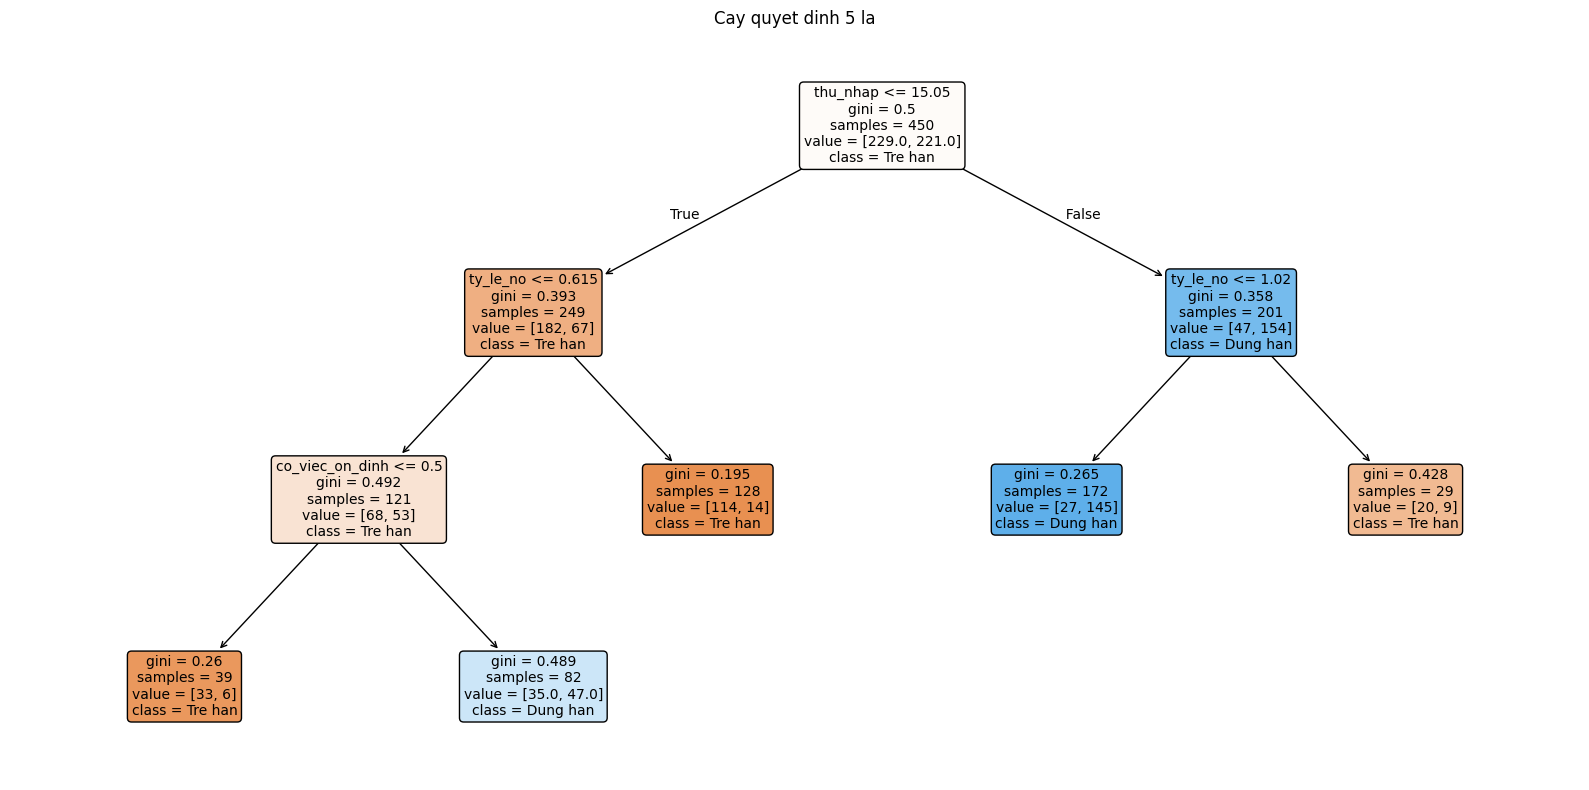

Da luu anh: cay_nam_la.png


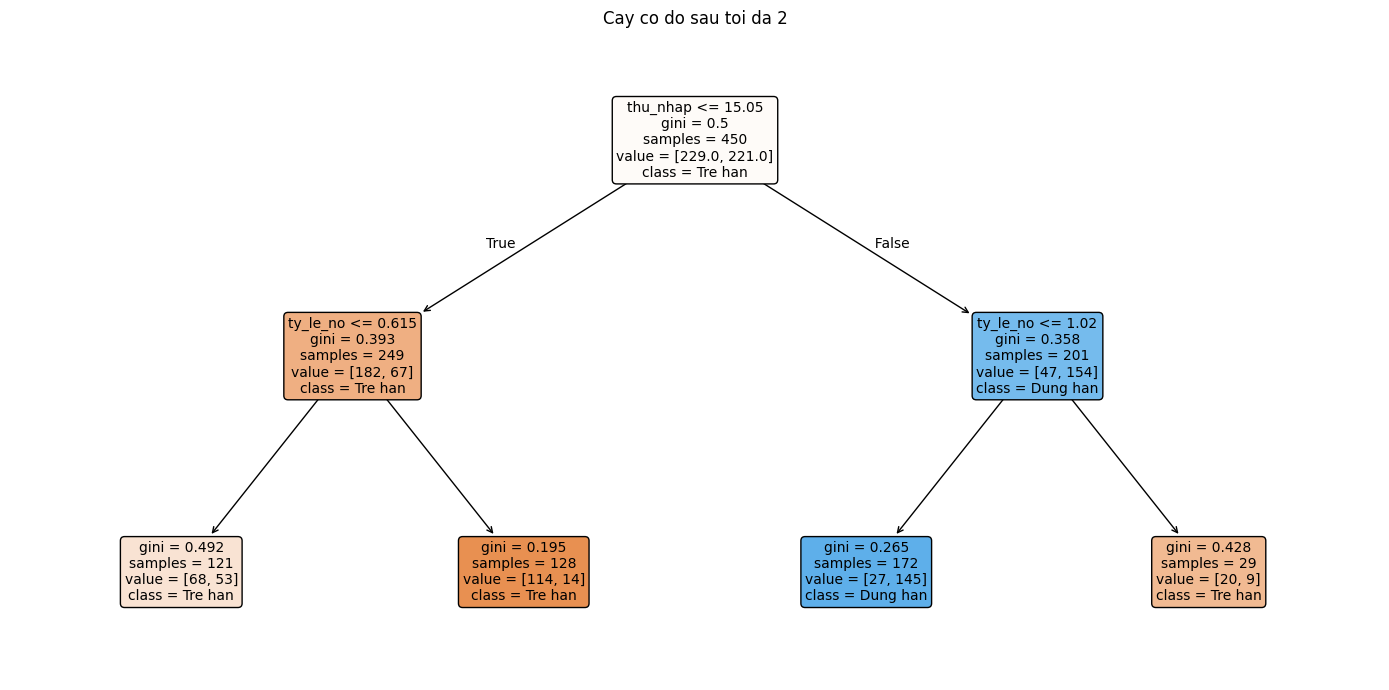

Da luu anh: cay_sau_2.png
Ket luan hai la ben trai: 0 0
Hai la co cung ket luan: True
Cay van tach de nhom khach o hai la co ty le nhan khac nhau, giup Gini giam.


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Dùng cùng dữ liệu và cách chia của phần thực hành
try:
    df = pd.read_csv('data/khach_vay.csv')
except FileNotFoundError:
    raise FileNotFoundError('Thiếu data/khach_vay.csv')
X = df.drop(columns='tra_dung_han')
y = df['tra_dung_han']
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Vẽ cây năm lá và lưu thành ảnh
cay_nam_la = DecisionTreeClassifier(max_leaf_nodes=5, random_state=0)
cay_nam_la.fit(X_tr, y_tr)
plt.figure(figsize=(16, 8))
plot_tree(cay_nam_la, feature_names=X.columns, class_names=['Tre han', 'Dung han'],
          filled=True, rounded=True, fontsize=10)
plt.title('Cay quyet dinh 5 la')
plt.tight_layout()
plt.savefig('cay_nam_la.png', dpi=150)
plt.show()
print('Da luu anh: cay_nam_la.png')

# Cây sâu tối đa 2
cay_sau_2 = DecisionTreeClassifier(max_depth=2, random_state=0)
cay_sau_2.fit(X_tr, y_tr)
plt.figure(figsize=(14, 7))
plot_tree(cay_sau_2, feature_names=X.columns, class_names=['Tre han', 'Dung han'],
          filled=True, rounded=True, fontsize=10)
plt.title('Cay co do sau toi da 2')
plt.tight_layout()
plt.savefig('cay_sau_2.png', dpi=150)
plt.show()
print('Da luu anh: cay_sau_2.png')

# Kiểm tra hai lá con của nhánh bên trái
cau_truc = cay_sau_2.tree_
trai = cau_truc.children_left[0]
if trai != -1 and cau_truc.children_left[trai] != -1:
    a = cau_truc.children_left[trai]
    b = cau_truc.children_right[trai]
    lop_a = int(cay_sau_2.classes_[np.argmax(cau_truc.value[a, 0])])
    lop_b = int(cay_sau_2.classes_[np.argmax(cau_truc.value[b, 0])])
    print('Ket luan hai la ben trai:', lop_a, lop_b)
    print('Hai la co cung ket luan:', lop_a == lop_b)
    print('Cay van tach de nhom khach o hai la co ty le nhan khac nhau, giup Gini giam.')
else:
    print('Nhanh trai khong tach thanh hai la trong lan chay nay.')


**Nhận xét**

- Hai lá bên trái đều dự đoán lớp 0, nhưng cây vẫn chia vì tỷ lệ trả nợ đúng hạn ở hai lá khác nhau, giúp giảm Gini.

### Bài tập 2 - Tự tìm câu hỏi gốc bằng Gini

In [9]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

def gini(nhan):
    if len(nhan) == 0:
        return 0.0
    p = np.mean(nhan == 1)
    return 1 - p**2 - (1 - p)**2

def tim_cau_hoi(X, y):
    """Dò mọi cột và ngưỡng, tìm cách chia làm giảm Gini nhiều nhất."""
    y = np.asarray(y)
    gini_goc = gini(y)
    ket_qua = None
    for cot in X.columns:
        gia_tri = np.asarray(X[cot], dtype=float)
        cac_muc = np.unique(gia_tri)
        for a, b in zip(cac_muc[:-1], cac_muc[1:]):
            nguong = (a + b) / 2
            ben_trai = gia_tri <= nguong
            y_trai = y[ben_trai]
            y_phai = y[~ben_trai]
            gini_moi = (len(y_trai) * gini(y_trai) + len(y_phai) * gini(y_phai)) / len(y)
            muc_giam = gini_goc - gini_moi
            if ket_qua is None or muc_giam > ket_qua[2] + 1e-12:
                ket_qua = (cot, nguong, muc_giam)
    return ket_qua

df = pd.read_csv('data/khach_vay.csv')
X = df.drop(columns='tra_dung_han')
y = df['tra_dung_han']
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
cot, nguong, muc_giam = tim_cau_hoi(X_tr, y_tr)
print(f'Tu tinh: {cot} <= {nguong:.2f}, Gini giam {muc_giam:.4f}')

# Đối chiếu với cây một tầng của scikit-learn
cay = DecisionTreeClassifier(max_depth=1, random_state=0).fit(X_tr, y_tr)
cot_may = X_tr.columns[cay.tree_.feature[0]]
nguong_may = cay.tree_.threshold[0]
print(f'Scikit-learn: {cot_may} <= {nguong_may:.2f}')
print('Trung ket qua:', cot == cot_may and np.isclose(nguong, nguong_may))


Tu tinh: thu_nhap <= 15.05, Gini giam 0.1221
Scikit-learn: thu_nhap <= 15.05
Trung ket qua: True


**Nhận xét**

- Hàm tự viết tìm được `thu_nhap <= 15.05`, trùng với scikit-learn. Đây là ngưỡng giúp giảm Gini nhiều nhất trên tập học.

### Bài tập 3 - So sánh Gini và Entropy

In [10]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv('data/khach_vay.csv')
X = df.drop(columns='tra_dung_han')
y = df['tra_dung_han']
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
for kieu in ['gini', 'entropy']:
    diem_cv = {}
    for do_sau in range(1, 16):
        cay = DecisionTreeClassifier(max_depth=do_sau, criterion=kieu, random_state=0)
        diem_cv[do_sau] = cross_val_score(cay, X_tr, y_tr, cv=5).mean()
    do_sau_tot = max(diem_cv, key=diem_cv.get)
    cay = DecisionTreeClassifier(max_depth=do_sau_tot, criterion=kieu, random_state=0)
    cay.fit(X_tr, y_tr)
    acc = accuracy_score(y_te, cay.predict(X_te))
    print(f'{kieu}: do sau tot nhat = {do_sau_tot}, CV = {diem_cv[do_sau_tot]:.4f}, Test = {acc:.4f}')


gini: do sau tot nhat = 5, CV = 0.8333, Test = 0.8533
entropy: do sau tot nhat = 5, CV = 0.8222, Test = 0.8467


**Nhận xét**

- Gini và Entropy đều chọn độ sâu 5. Accuracy lần lượt là 85,33% và 84,67% nên kết quả chỉ chênh lệch nhẹ.

### Bài tập 4 - Cắt tỉa bằng min_samples_leaf

In [11]:
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv('data/khach_vay.csv')
X = df.drop(columns='tra_dung_han')
y = df['tra_dung_han']
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Chọn leaf bằng 5-fold CV trên tập học
cv_diem = {}
for so_khach in [1, 2, 5, 10, 20, 40]:
    cay = DecisionTreeClassifier(min_samples_leaf=so_khach, random_state=0)
    cv_diem[so_khach] = cross_val_score(cay, X_tr, y_tr, cv=5).mean()
    print(f'min_samples_leaf={so_khach:2d} | CV={cv_diem[so_khach]:.4f}')
so_tot = max(cv_diem, key=cv_diem.get)

# Chấm trên test sau khi đã chọn xong
cay_la = DecisionTreeClassifier(min_samples_leaf=so_tot, random_state=0).fit(X_tr, y_tr)
cay_sau_5 = DecisionTreeClassifier(max_depth=5, random_state=0).fit(X_tr, y_tr)
a = accuracy_score(y_te, cay_la.predict(X_te))
b = accuracy_score(y_te, cay_sau_5.predict(X_te))
print(f'Leaf tot nhat: {so_tot}, Accuracy test = {a:.4f}')
print(f'Cay do sau 5: Accuracy test = {b:.4f}')
print('Tot hon:', 'min_samples_leaf' if a > b else ('max_depth=5' if b > a else 'Ngang nhau'))


min_samples_leaf= 1 | CV=0.7733
min_samples_leaf= 2 | CV=0.7822
min_samples_leaf= 5 | CV=0.8067
min_samples_leaf=10 | CV=0.8089
min_samples_leaf=20 | CV=0.8089
min_samples_leaf=40 | CV=0.7133
Leaf tot nhat: 10, Accuracy test = 0.8467
Cay do sau 5: Accuracy test = 0.8533
Tot hon: max_depth=5


**Nhận xét**

- `min_samples_leaf=10` có CV cao nhất trong các giá trị thử. Test Accuracy 84,67%, thấp hơn một chút so với cây sâu 5 là 85,33%.

### Bài tập 5 - Độ quan trọng bằng permutation importance

In [12]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

df = pd.read_csv('data/khach_vay.csv')
X = df.drop(columns='tra_dung_han')
y = df['tra_dung_han']
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Cùng cột ngẫu nhiên của mục 7, tạo thêm dữ liệu test bằng cùng RNG
rng = np.random.default_rng(0)
X_tr_nn = X_tr.copy()
X_te_nn = X_te.copy()
X_tr_nn['so_ngau_nhien'] = rng.random(len(X_tr))
X_te_nn['so_ngau_nhien'] = rng.random(len(X_te))

rung = RandomForestClassifier(n_estimators=200, random_state=0)
rung.fit(X_tr_nn, y_tr)
mdi = pd.Series(rung.feature_importances_, index=X_tr_nn.columns)
ket_qua = permutation_importance(
    rung, X_te_nn, y_te, n_repeats=20, random_state=0, scoring='accuracy'
)
perm = pd.Series(ket_qua.importances_mean, index=X_te_nn.columns)

bang = pd.DataFrame({'MDI': mdi, 'Permutation': perm})
bang['Hang MDI'] = bang['MDI'].rank(ascending=False, method='min').astype(int)
bang['Hang Permutation'] = bang['Permutation'].rank(ascending=False, method='min').astype(int)
print(bang.sort_values('Permutation', ascending=False).round(4).to_string())
print('Cot ngau nhien hang MDI:', bang.loc['so_ngau_nhien', 'Hang MDI'])
print('Cot ngau nhien hang Permutation:', bang.loc['so_ngau_nhien', 'Hang Permutation'])


                       MDI  Permutation  Hang MDI  Hang Permutation
thu_nhap            0.4269       0.3073         1                 1
ty_le_no            0.2696       0.1993         2                 2
co_viec_on_dinh     0.0773       0.1117         4                 3
so_nguoi_phu_thuoc  0.0764       0.0497         5                 4
so_ngau_nhien       0.1499       0.0017         3                 5
Cot ngau nhien hang MDI: 3
Cot ngau nhien hang Permutation: 5


**Nhận xét**

- Cột ngẫu nhiên xếp hạng 3 theo MDI nhưng hạng 5 theo Permutation. Vì xáo trộn cột này gần như không làm giảm Accuracy nên nó không giúp ích nhiều khi dự đoán.

### Bài tập 6 - Random Forest cho hồi quy giá nhà

In [13]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

df = pd.read_csv('data/gia_nha.csv')
X = df[['dien_tich']]
y = df['gia']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

mo_hinh = {
    'Cay sau 3': DecisionTreeRegressor(max_depth=3, random_state=0),
    'Random Forest 200': RandomForestRegressor(n_estimators=200, random_state=0),
    'Linear Regression': LinearRegression(),
}
for ten, m in mo_hinh.items():
    m.fit(X_tr, y_tr)
    mae = mean_absolute_error(y_te, m.predict(X_te))
    gia_250 = m.predict(pd.DataFrame({'dien_tich': [250.0]}))[0]
    print(f'{ten:18s} | MAE={mae:.4f} ty | Can 250m2={gia_250:.2f} ty')
print('Gia cao nhat trong train:', round(y_tr.max(), 2), 'ty')


Cay sau 3          | MAE=0.5039 ty | Can 250m2=9.40 ty
Random Forest 200  | MAE=0.4559 ty | Can 250m2=9.20 ty
Linear Regression  | MAE=0.2578 ty | Can 250m2=19.91 ty
Gia cao nhat trong train: 9.74 ty


**Nhận xét**

- MAE của rừng là 0,4559 tỷ, tốt hơn cây sâu 3 (0,5039) nhưng kém đường thẳng (0,2578). Rừng đoán căn 250 m² là 9,20 tỷ; do dựa vào giá trong các lá nên rừng không ngoại suy như đường thẳng.